# Driving CNN: camera image → steering, throttle

Behavioural cloning: the autopilot in `test.py` drove the car and recorded every camera
frame with the controls it sent. This network learns to produce the same controls from
the image alone.

In [1]:
import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(0)
np.random.seed(0)

DATASET = "dataset"
CROP_TOP = 40             # rows of ceiling/sky removed from the 160x120 frame
TARGETS = ["steering", "throttle"]
VAL_SESSION = "20261027_113044"   # one whole run kept aside for validation

## 1. Load every recording session

Consecutive frames are nearly identical, so a random split would put almost the same image
in train and validation. Holding out a **whole session** gives an honest score.

In [2]:
def load_session(folder):
    df = pd.read_csv(os.path.join(folder, "labels.csv"))
    images = np.stack([np.asarray(Image.open(os.path.join(folder, p)).convert("RGB"))
                       for p in df.image])
    return images[:, CROP_TOP:], df[TARGETS].values.astype(np.float32)

train_x, train_y, val_x, val_y = [], [], [], []
for folder in sorted(glob.glob(os.path.join(DATASET, "*", ""))):
    x, y = load_session(folder)
    is_val = os.path.basename(os.path.normpath(folder)) == VAL_SESSION
    (val_x if is_val else train_x).append(x)
    (val_y if is_val else train_y).append(y)
    print(f"{folder}: {len(x)} frames{'  (validation)' if is_val else ''}")

train_x, train_y = np.concatenate(train_x), np.concatenate(train_y)
val_x, val_y = np.concatenate(val_x), np.concatenate(val_y)
print("train", train_x.shape, "val", val_x.shape)

dataset\20261026_235033\: 1257 frames


dataset\20261027_112914\: 1004 frames


dataset\20261027_113044\: 669 frames  (validation)


dataset\20261027_113134\: 1837 frames
train (4098, 80, 160, 3) val (669, 80, 160, 3)


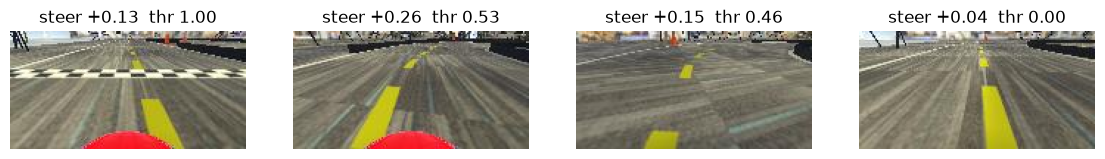

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(14, 2.5))
for ax, i in zip(axes, np.linspace(0, len(train_x) - 1, 4).astype(int)):
    ax.imshow(train_x[i])
    ax.set_title(f"steer {train_y[i, 0]:+.2f}  thr {train_y[i, 1]:.2f}")
    ax.axis("off")
plt.show()

## 2. Augmentation: horizontal flip

The track turns mostly one way (mean steering ≈ +0.2). Adding a mirrored copy of every
training frame with the steering negated balances left and right turns.

In [4]:
def to_tensor(images):
    return torch.from_numpy(images).permute(0, 3, 1, 2).float() / 255.0   # N, C, H, W

flipped_x = train_x[:, :, ::-1]
flipped_y = train_y * np.array([-1.0, 1.0], dtype=np.float32)

X_train = to_tensor(np.concatenate([train_x, flipped_x]))
Y_train = torch.from_numpy(np.concatenate([train_y, flipped_y]))
X_val, Y_val = to_tensor(val_x), torch.from_numpy(val_y)

train_loader = DataLoader(TensorDataset(X_train, Y_train), batch_size=64, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, Y_val), batch_size=256)
print("training samples:", len(X_train))

training samples: 8196


## 3. The model

Four convolution blocks shrink the 80×160 image to a small feature map, then two
fully-connected layers output steering (tanh, −1..1) and throttle (sigmoid, 0..1).

In [5]:
class DrivingCNN(nn.Module):
    def __init__(self):
        super().__init__()
        def block(c_in, c_out):
            return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1),
                                 nn.BatchNorm2d(c_out), nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 16), block(16, 32), block(32, 64), block(64, 64))
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.3),
                                  nn.Linear(64 * 5 * 10, 64), nn.ReLU(),
                                  nn.Linear(64, 2))

    def forward(self, x):
        out = self.head(self.features(x))
        return torch.stack([torch.tanh(out[:, 0]), torch.sigmoid(out[:, 1])], dim=1)

model = DrivingCNN()
print(model)
print("parameters:", sum(p.numel() for p in model.parameters()))

DrivingCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (3): Sequential(
      (0): C

## 4. Training

In [6]:
EPOCHS = 15
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

def evaluate(loader):
    model.eval()
    total, preds = 0.0, []
    with torch.no_grad():
        for x, y in loader:
            p = model(x)
            total += loss_fn(p, y).item() * len(x)
            preds.append(p)
    return total / len(loader.dataset), torch.cat(preds)

history = {"train": [], "val": []}
best_val = float("inf")
for epoch in range(1, EPOCHS + 1):
    model.train()
    running = 0.0
    for x, y in train_loader:
        optimizer.zero_grad()
        loss = loss_fn(model(x), y)
        loss.backward()
        optimizer.step()
        running += loss.item() * len(x)
    train_loss = running / len(train_loader.dataset)
    val_loss, _ = evaluate(val_loader)
    history["train"].append(train_loss)
    history["val"].append(val_loss)
    if val_loss < best_val:
        best_val = val_loss
        torch.save(model.state_dict(), "driving_cnn.pt")
    print(f"epoch {epoch:2d}  train {train_loss:.4f}  val {val_loss:.4f}"
          f"{'  *saved' if val_loss == best_val else ''}")

epoch  1  train 0.6062  val 0.8252  *saved


epoch  2  train 0.1395  val 0.0326  *saved


epoch  3  train 0.0258  val 0.0278  *saved


epoch  4  train 0.0211  val 0.0335


epoch  5  train 0.0195  val 0.0191  *saved


...

epoch 11  train 0.0135  val 0.0244


epoch 12  train 0.0132  val 0.0299


epoch 13  train 0.0128  val 0.0168


epoch 14  train 0.0125  val 0.0143


epoch 15  train 0.0116  val 0.0274


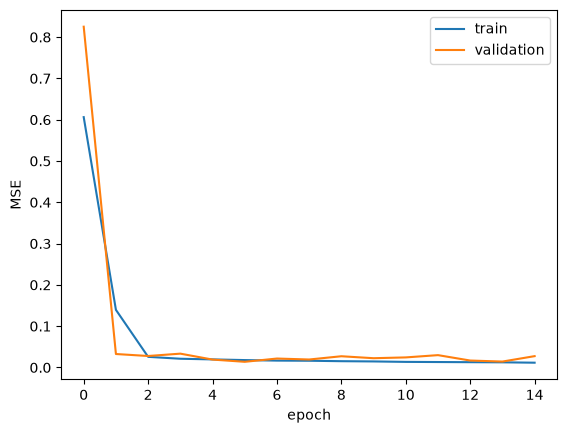

In [7]:
plt.plot(history["train"], label="train")
plt.plot(history["val"], label="validation")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.legend(); plt.show()

## 5. Evaluation on the held-out session

The baseline is the error you would get by always predicting the average value.
The model is only useful if it beats it clearly.

steering  MAE 0.043  (baseline 0.266)  correlation 0.99
throttle  MAE 0.129  (baseline 0.168)  correlation 0.69


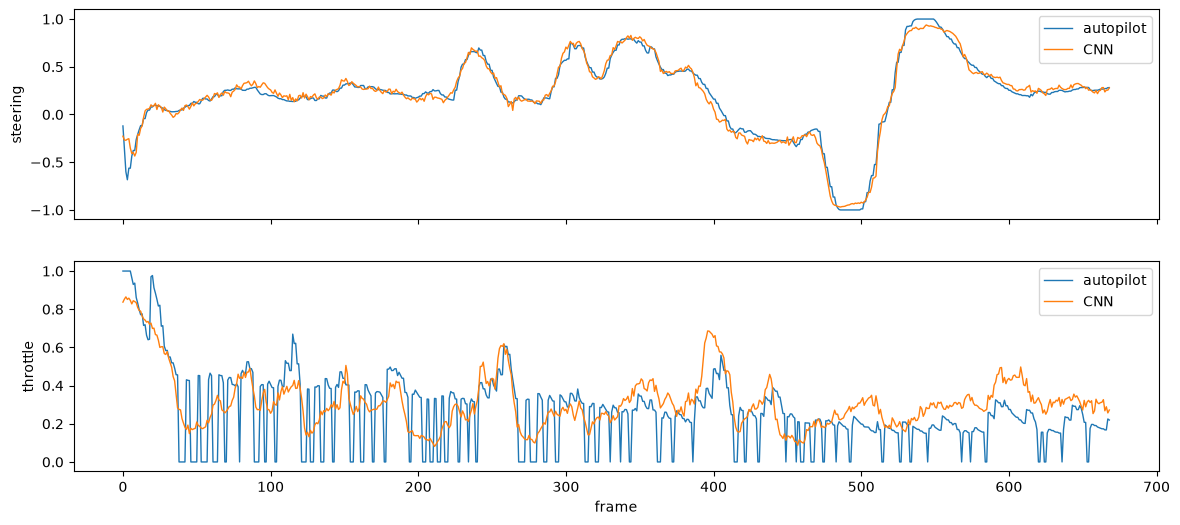

In [8]:
model.load_state_dict(torch.load("driving_cnn.pt"))
_, pred = evaluate(val_loader)
pred = pred.numpy()

for i, name in enumerate(TARGETS):
    mae = np.abs(pred[:, i] - val_y[:, i]).mean()
    baseline = np.abs(train_y[:, i].mean() - val_y[:, i]).mean()
    corr = np.corrcoef(pred[:, i], val_y[:, i])[0, 1]
    print(f"{name:9s} MAE {mae:.3f}  (baseline {baseline:.3f})  correlation {corr:.2f}")

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
for ax, i, name in zip(axes, range(2), TARGETS):
    ax.plot(val_y[:, i], label="autopilot", lw=1)
    ax.plot(pred[:, i], label="CNN", lw=1)
    ax.set_ylabel(name); ax.legend(loc="upper right")
axes[1].set_xlabel("frame")
plt.show()